# 00 — Structure and attractors of the extended ICD model

`model/ICD_extend.bnd` is a MaBoSS model of immunogenic cell death (ICD), simulated with UPMaBoSS
(`ICD_extend.upp`). The `.bnd` is read directly with `maboss_visualize` (`mv.read_network` →
`read_bnd`), so no `.bnet` export is needed for the network figures. The attractor analysis uses
an asynchronous Boolean abstraction of the rates (Step 2).

In [1]:
%matplotlib inline

import itertools
import os
import re
import sys
from pathlib import Path

import biodivine_aeon as ba
import maboss_visualize as mv
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import seaborn as sns

# Work from the repo root wherever the notebook lives (safe to re-run); plot_style.py is in analysis/
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "model").is_dir())
os.chdir(ROOT)
if str(ROOT / "analysis") not in sys.path:
    sys.path.insert(0, str(ROOT / "analysis"))
import plot_style

plt.rcParams["figure.dpi"] = 300   # keeps the saved notebook small; raise it for real figures
plot_style.setup("00_model_structure")   # Helvetica; saves to plots/00_model_structure/
MODEL = Path("model")
BND, UPP = MODEL / "ICD_extend.bnd", MODEL / "ICD_extend.upp"
print("maboss_visualize", mv.__version__)
print(sorted(p.name for p in MODEL.iterdir()))

# .bnd + the UPMaBoSS couplings of the .upp
net = mv.read_network(BND, upp=UPP)
net

maboss_visualize 0.1.0.dev0
['ICD_extend.bnd', 'ICD_extend.cfg', 'ICD_extend.upp', 'ICD_extend_DownCD28.upp', 'ICD_extend_UpIL2_rec.upp', 'ICD_phenomenological.bnd', 'ICD_phenomenological.cfg', 'ICD_phenomenological.upp']


<Network 'ICD_extend': 52 nodes, 166 edges, no layout>

## Step 1 — The influence graph

A `.bnd` node is defined by its rates, not only by its `logic`. `read_bnd` takes the edges from
`logic`, `rate_up` and `rate_down`, so the nodes driven only by their rates (`DyingTumor`,
`Division`, `Death`) get regulators too. An edge's sign comes from the truth table of the rates:
an activator can only raise `rate_up` or lower `rate_down`. **Dual** edges are therefore real here:
they are the cell-identity checks such as `IFNg_rec = (cd8 & !cd4) | (!cd8 & cd4)`, not a parsing
failure.

With `upp=`, every `$u_X u= … p[(A) = (1)]` update of the `.upp` becomes an edge `A → X` with
`population=True`. These are the intercellular couplings of UPMaBoSS (`CALR_o → LRP1`,
`HMGB1_o → TLR4`, `IL2_o → IL2_rec` …). Without them the network splits into disconnected parts.

The `.bnd` stores no layout or style. Node colours give the role of each node. One hierarchical
layout is computed here and stored in `net.pos`, so every later network figure reuses it.

In [2]:
node_df, edge_df = net.to_frames()

# The .bnd stores no style: group the nodes by their role in the model
IDENTITY = ["Tumor", "DC", "cd4", "cd8"]     # cell type: both rates 0, so fixed
TREATMENT = ["ChemoT"]                        # only decays (rate_down = $degChemo)
FATE = ["Division", "Death"]                  # UPMaBoSS division / death nodes (.upp)
CELL_STATE = ["DyingTumor", "aDC", "cd4_Act", "Th1", "Th2", "Th17", "Treg", "preCTL", "CTL"]


def role(node):
    if node in IDENTITY:
        return "cell identity"
    if node in TREATMENT:
        return "treatment"
    if node in FATE:
        return "cell fate (UPMaBoSS)"
    if node in CELL_STATE:
        return "cell state"
    if node.endswith("_o"):
        return "secreted / exposed signal"
    return "receptor / sensor"


assert set(IDENTITY + TREATMENT + FATE + CELL_STATE) <= set(net.nodes)
node_df["role"] = [role(n) for n in node_df.index]
nx.set_node_attributes(net.graph, node_df["role"].to_dict(), "role")
print(node_df["role"].value_counts().to_string(), "\n")

sign_names = {1: "activation", -1: "inhibition", 0: "dual"}
print(pd.crosstab(edge_df["sign"].map(sign_names),
                  edge_df["population"].map({False: "within a cell", True: "population (.upp)"})))
edge_df[edge_df["sign"] == 0]

role
receptor / sensor            18
secreted / exposed signal    18
cell state                    9
cell identity                 4
cell fate (UPMaBoSS)          2
treatment                     1 

population  population (.upp)  within a cell
sign                                        
activation                 18            130
dual                        0              6
inhibition                  1             11


,source,target,sign,population
25,cd4,IFNg_rec,0,False
28,cd4,CXCR3,0,False
29,cd4,CD28,0,False
41,cd8,IFNg_rec,0,False
42,cd8,CXCR3,0,False
43,cd8,CD28,0,False


In [3]:
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

# One hierarchical layout, stored on the network and reused by every later figure
net = net.with_layout("dot", args="-Gnodesep=0.6 -Granksep=1.3")

ROLE_COLORS = {
    "cell identity": "#4c78a8",
    "treatment": "#f58518",
    "cell state": "#e45756",
    "receptor / sensor": "#72b7b2",
    "secreted / exposed signal": "#eeca3b",
    "cell fate (UPMaBoSS)": "#9d755d",
}
POP_COLOR = "#8e44ad"
role_fill = {n: ROLE_COLORS[r] for n, r in net.nodes(data="role")}
pop_edges = {(u, v): POP_COLOR for u, v, pop in net.edges(data="population") if pop}
EDGE_HANDLES = [
    Line2D([], [], color="#2ca02c", lw=2, label="activation"),
    Line2D([], [], color="#d62728", lw=2, label="inhibition"),
    Line2D([], [], color="#4575b4", lw=2, label="dual (cell-identity check)"),
    Line2D([], [], color=POP_COLOR, lw=2, label="population coupling (.upp)"),
]


def draw_structure(layout, figsize, title):
    ax = mv.draw_network(net, layout=layout, figsize=figsize, node_size=500,
                         node_color=role_fill, edge_color=pop_edges, legend=False,
                         label_kw={"font_size": 10}, title=title)
    ax.legend(handles=[Patch(fc=c, ec="#4d4d4d", label=r) for r, c in ROLE_COLORS.items()]
              + EDGE_HANDLES, loc="upper left", bbox_to_anchor=(1.0, 1.0), frameon=False,
              fontsize=13)
    ax.title.set_fontsize(18)
    return ax

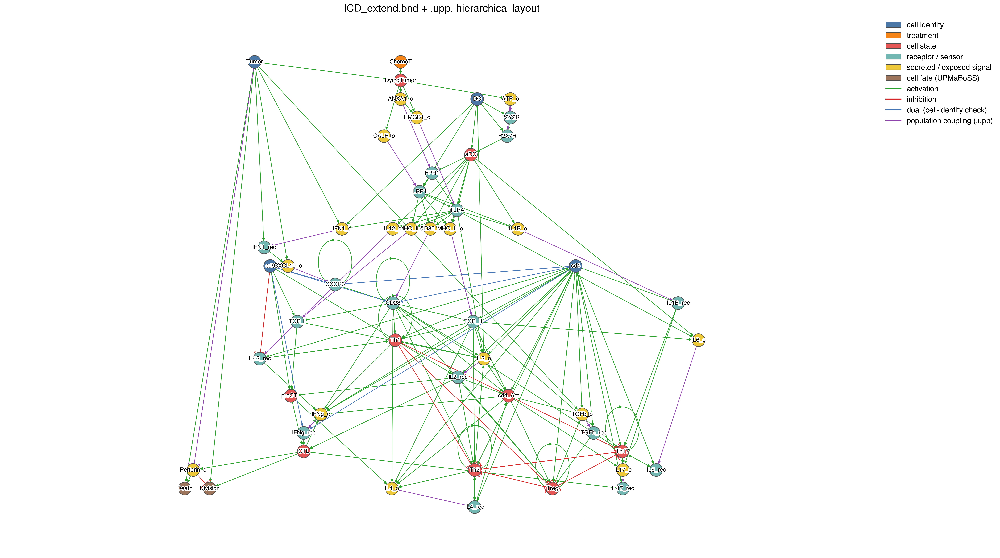

In [4]:
ax = draw_structure(None, (22, 14), "ICD_extend.bnd + .upp, hierarchical layout")
plot_style.save_fig(ax.figure, "network_hierarchical_layout")

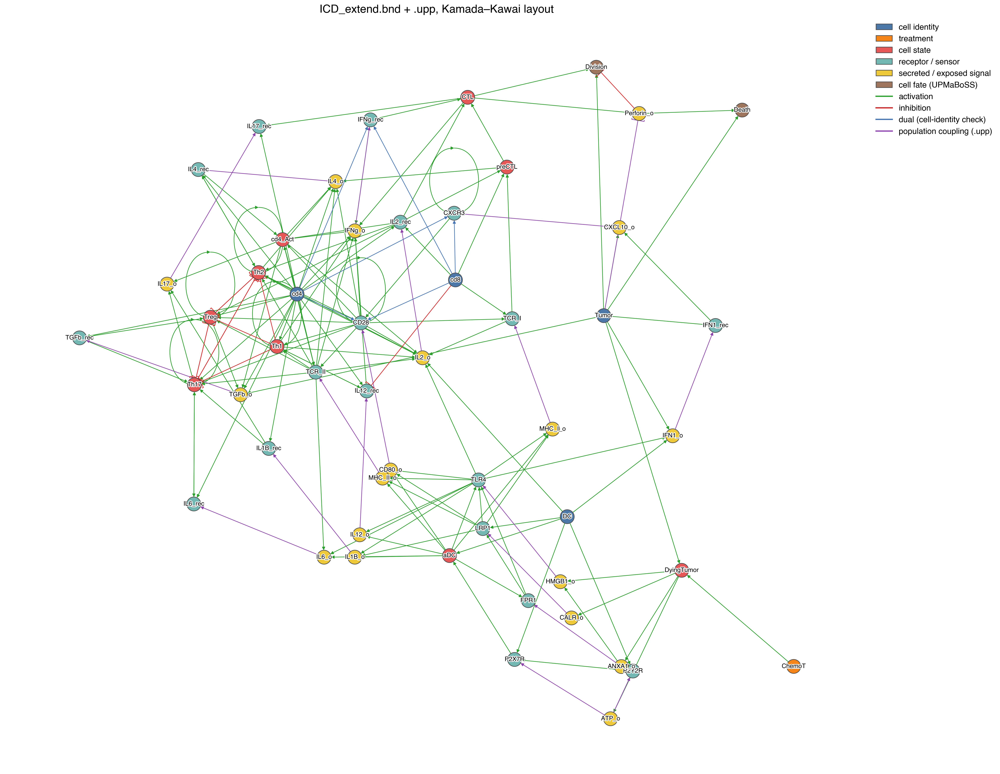

In [5]:
ax = draw_structure("kamada_kawai", (20, 18), "ICD_extend.bnd + .upp, Kamada–Kawai layout")
plot_style.save_fig(ax.figure, "network_kamada_kawai_layout")

## Step 2 — From rates to a Boolean model, and its attractors

**Boolean abstraction.** `mv.bnd_to_bnet` turns each node's rates into the asynchronous update
`X* = (!X & up) | (X & !down)`, where `up` / `down` mean "`rate_up` / `rate_down` is non-zero".
Parameter values are not used, only whether a rate can be non-zero. `rate_up = @logic ? $u : 0`
with `rate_down = @logic ? 0 : $d` gives back `X* = logic`. `rate_down = 0` gives an irreversible
`X* = X | logic` (`aDC`, most receptors, the T-cell states). `ChemoT` only decays (`X* = 0`).

**Why not enumerate every attractor (biobalm).** Because so many nodes are irreversible, the full
state space holds millions of fixed points that only remember impossible initial states (`aDC` ON
in a cell that is not a DC). They are counted below. Here attractors are computed only from the
initial conditions of the `.cfg`, by forward reachability with AEON (installed with biobalm).

**Population → one copy per cell type.** UPMaBoSS simulates a population of tumour cells, DCs,
CD4 and CD8 T cells, coupled through `p[…]` in the `.upp`. Reading that population as one
meta-cell breaks the identity checks (`IL12_rec = cd4 & !cd8` is never true in a cell that is both
CD4 and CD8). So the model is copied once per cell type: `aDC__DC` is `aDC` in the DC. A population
term `p[(A) = (1)]` becomes "`A` is ON in at least one cell type", i.e. an OR over the copies.
Population sizes are lost: a signal is either present or absent.

**Scenarios.** A scenario says which cell types are present, and whether the tumour cells
received chemotherapy (`ChemoT`, ON in tumour cells in the `.cfg`). These are the inputs of the
truth table below. Every other node starts OFF, as in the `.cfg`, except `IL1B_o` (50 / 50 in the
`.cfg`), which starts free.

The attractor table has **one row per attractor and one column per `node__cell` variable**, with
values in $\{0, 1\}$ and 0.5 for a variable that oscillates inside its attractor.

In [6]:
# Asynchronous Boolean abstraction of the rates; each p[...] of the .upp becomes a free variable p_X
cell_rules = dict(line.split(", ", 1)
                  for line in mv.bnd_to_bnet(BND, upp=UPP, population="variables").splitlines()[1:])
pop_vars = sorted(v for v in cell_rules if v.startswith("p_"))
for v in pop_vars:
    del cell_rules[v]
assert all(v[2:] in net for v in pop_vars), "only p[(X) = (1)] terms are expected in this .upp"
print(len(pop_vars), "population terms:", ", ".join(pop_vars), "\n")

# Why not all attractors: the population read as one cell has this many fixed points
one_cell = ba.BooleanNetwork.from_bnet(mv.bnd_to_bnet(BND, upp=UPP)).infer_valid_graph()
n_fixed = ba.FixedPoints.symbolic_vertices(ba.AsynchronousGraph(one_cell)).cardinality()
print(f"fixed points over the whole state space (one meta-cell): {n_fixed:,}")

19 population terms: p_ANXA1_o, p_ATP_o, p_CALR_o, p_CD80_o, p_CXCL10_o, p_HMGB1_o, p_IFN1_o, p_IFNg_o, p_IL12_o, p_IL17_o, p_IL1B_o, p_IL2_o, p_IL4_o, p_IL6_o, p_MHC_II_o, p_MHC_I_o, p_Perforin_o, p_TGFb_o, p_Tumor 



fixed points over the whole state space (one meta-cell): 130,448,664


In [7]:
# --- One copy of the model per cell type, joined by the population terms ------------------
COMPARTMENTS = {"Tumor": "Tumor", "DC": "DC", "CD4": "cd4", "CD8": "cd8"}  # cell type -> identity node
TOKEN = re.compile(r"[A-Za-z_]\w*")


def var(node, cell):
    return f"{node}__{cell}"


def in_cell(rule, cell):
    # Rule of the copy in `cell`; a population term p_X becomes "X in any cell type"
    def rename(m):
        name = m.group(0)
        if name in pop_vars:
            return "(" + " | ".join(var(name[2:], c) for c in COMPARTMENTS) + ")"
        return var(name, cell)
    return TOKEN.sub(rename, rule)


multi_bnet = "targets, factors\n" + "\n".join(
    f"{var(node, cell)}, {in_cell(rule, cell)}"
    for cell in COMPARTMENTS for node, rule in cell_rules.items())
stg = ba.AsynchronousGraph(ba.BooleanNetwork.from_bnet(multi_bnet).infer_valid_graph())
variables = stg.network_variable_names()
print(len(variables), "variables =", len(cell_rules), "nodes ×", len(COMPARTMENTS), "cell types")
print("e.g.", var("LRP1", "DC"), "* =", in_cell(cell_rules["LRP1"], "DC"))

208 variables = 52 nodes × 4 cell types
e.g. LRP1__DC * = LRP1__DC | (DC__DC & FPR1__DC & (CALR_o__Tumor | CALR_o__DC | CALR_o__CD4 | CALR_o__CD8))


In [8]:
# --- Scenarios: which cell types are present, and chemotherapy of the tumour cells --------
SCENARIO_COLS = ["Tumor", "ChemoT", "DC", "CD4", "CD8"]
scenarios = [dict(zip(SCENARIO_COLS, s)) for s in itertools.product((0, 1), repeat=len(SCENARIO_COLS))
             if s[0] or not s[1]]   # chemotherapy is given to tumour cells only
SHORT = {"Tumor": "T", "ChemoT": "Chemo", "DC": "DC", "CD4": "CD4", "CD8": "CD8"}


def scenario_name(sc):
    return "+".join(SHORT[k] for k in SCENARIO_COLS if sc[k]) or "none"


def initial_space(sc):
    # .cfg initial condition: everything OFF but the cell identities and ChemoT; IL1B_o free
    init = {v: 0 for v in variables}
    for cell, identity in COMPARTMENTS.items():
        init[var(identity, cell)] = sc[cell]
        del init[var("IL1B_o", cell)]
    init[var("ChemoT", "Tumor")] = sc["ChemoT"]
    return stg.mk_subspace(init)


rows = []
for sc in scenarios:
    reachable = ba.Reachability.reach_fwd(stg, initial_space(sc))
    for att in ba.Attractors.attractors(stg, reachable):
        space = att.vertices().enclosing_named_subspace()   # free variable = oscillates
        rows.append({**sc, "scenario": scenario_name(sc), "n_states": att.vertices().cardinality(),
                     **{v: float(space[v]) if v in space else 0.5 for v in variables}})

att_df = pd.DataFrame(rows)
att_df.index = [f"a{i + 1:02d} {s}" for i, s in enumerate(att_df["scenario"])]
attractor_states = att_df[variables]
scenario_df = att_df[SCENARIO_COLS + ["scenario", "n_states"]]
print(f"{len(att_df)} attractors from {len(scenarios)} scenarios "
      f"({(att_df['n_states'] > 1).sum()} cyclic)")
att_df.groupby("scenario", sort=False).size().rename("n attractors").to_frame().T

52 attractors from 24 scenarios (4 cyclic)


scenario,none,CD8,CD4,CD4+CD8,DC,DC+CD8,DC+CD4,DC+CD4+CD8,T,T+CD8,...,T+DC+CD4,T+DC+CD4+CD8,T+Chemo,T+Chemo+CD8,T+Chemo+CD4,T+Chemo+CD4+CD8,T+Chemo+DC,T+Chemo+DC+CD8,T+Chemo+DC+CD4,T+Chemo+DC+CD4+CD8
n attractors,1,1,2,2,1,1,2,2,1,1,...,2,2,2,2,4,4,2,2,6,6


We then visualize the attractor states with a clustered heatmap. Variables that take the same value
in every attractor carry no information and are dropped here (they are counted below).

57 of 208 variables differ between attractors


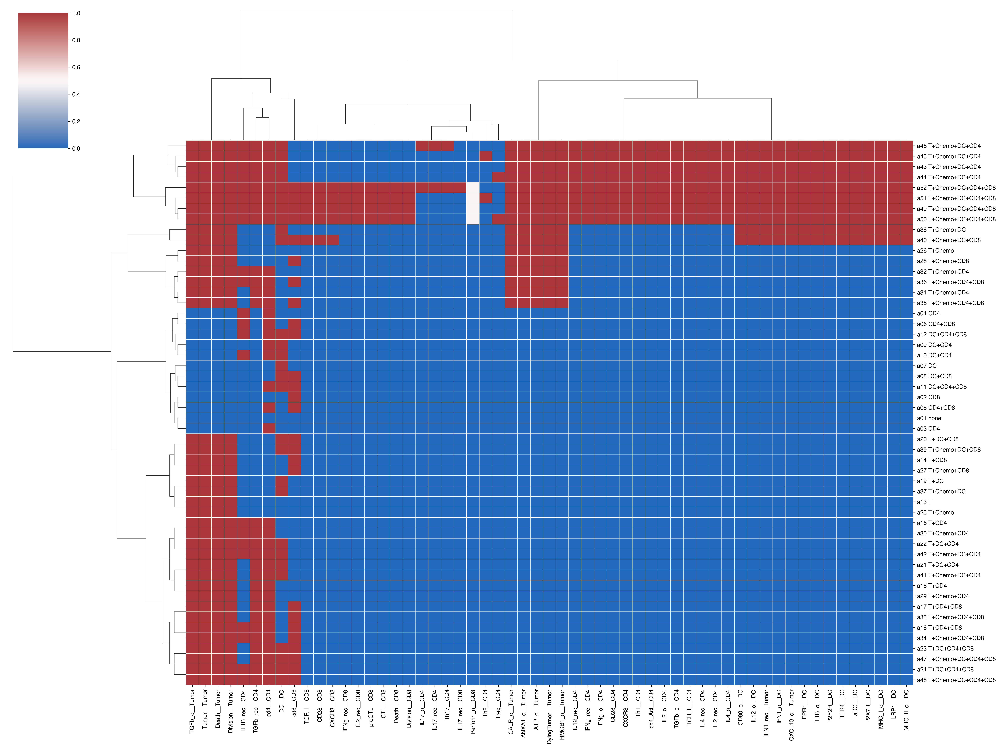

In [9]:
varying = attractor_states.columns[attractor_states.nunique() > 1]
print(f"{len(varying)} of {attractor_states.shape[1]} variables differ between attractors")
g = sns.clustermap(attractor_states[varying], method="ward", metric="euclidean", cmap="vlag",
                   linewidths=0.1, figsize=(24, 18), xticklabels=True, yticklabels=True)
plot_style.save_fig(g.figure, "attractor_clustermap")

### Which nodes are constant and which cycle?

Each `node__cell` variable is classified from its column in `attractor_states`, using only the
attractors in which that cell type is present (a missing cell type is trivially all OFF):

* **constant**: fixed (0 or 1) in every attractor. It can be the same value everywhere (*always
  OFF* / *always ON*) or a different value depending on the attractor (*ON or OFF*);
* **cycling**: oscillates (→ 0.5) in at least one attractor. The attractors come from AEON, so a free
  variable really takes both values inside its attractor.

One panel per cell type. Each bar shows, for one node, the share of the attractors in which it
is OFF, ON or cycling.

In [10]:
# --- Classify every node of every cell type from its values across the attractors -------
STATE_COLORS = {"OFF": "#2a78d6", "ON": "#e34948", "cycling": "#eda100"}
CLASS_ORDER = ["constant OFF", "constant ON", "constant, ON or OFF", "cycling"]
nodes = list(cell_rules)


def classify(values):
    # values: DataFrame[attractor × node] -> (fractions OFF/ON/cycling, class per node)
    fractions = pd.DataFrame({"OFF": (values == 0).mean(), "ON": (values == 1).mean(),
                              "cycling": (values == 0.5).mean()})
    cls = pd.Series(np.select(
        [fractions["cycling"] > 0, fractions["ON"] == 1, fractions["OFF"] == 1],
        ["cycling", "constant ON", "constant OFF"],
        default="constant, ON or OFF"), index=fractions.index, name="class")
    return fractions, cls


node_fractions, node_class = {}, {}
for cell in COMPARTMENTS:
    present = attractor_states[att_df[cell] == 1]
    values = present[[var(n, cell) for n in nodes]].set_axis(nodes, axis=1)
    node_fractions[cell], node_class[cell] = classify(values)
class_table = pd.DataFrame(node_class)
cycling_nodes = {cell: cls.index[cls == "cycling"].to_list() for cell, cls in node_class.items()}
print(class_table.apply(pd.Series.value_counts).reindex(CLASS_ORDER).fillna(0).astype(int))
print("\ncycling:", {c: v for c, v in cycling_nodes.items() if v})

                     Tumor  DC  CD4  CD8
constant OFF            41  39   31   40
constant ON              4   1    1    1
constant, ON or OFF      7  12   20   10
cycling                  0   0    0    1

cycling: {'CD8': ['Perforin_o']}


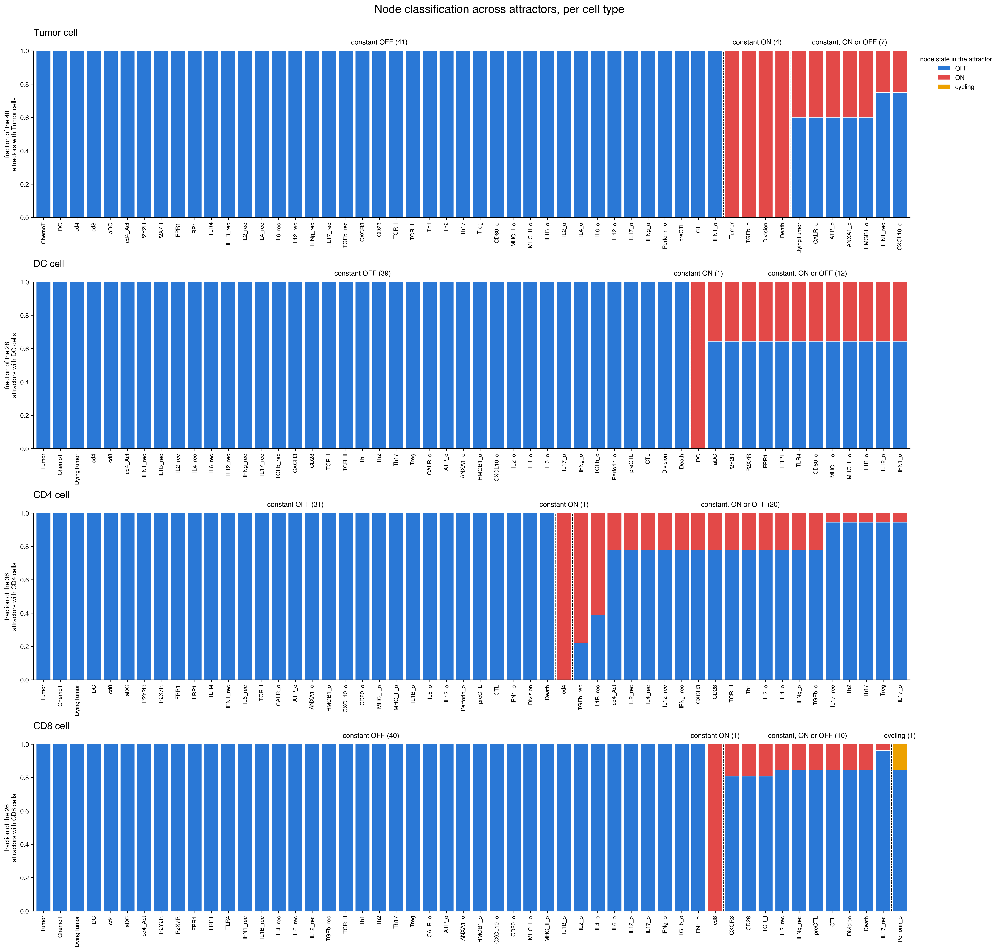

In [11]:
fig, axes = plt.subplots(len(COMPARTMENTS), 1, figsize=(22, 5.2 * len(COMPARTMENTS)))
for ax, cell in zip(axes, COMPARTMENTS):
    frac_all, cls_all = node_fractions[cell], node_class[cell]
    order = (frac_all.assign(cls=pd.Categorical(cls_all, CLASS_ORDER))
             .sort_values(["cls", "cycling", "ON"], ascending=[True, False, False]).index)
    frac, cls = frac_all.loc[order], cls_all.loc[order]
    x = np.arange(len(order))
    bottom = np.zeros(len(order))
    for state in ["OFF", "ON", "cycling"]:
        ax.bar(x, frac[state], bottom=bottom, width=0.85, color=STATE_COLORS[state],
               edgecolor="white", linewidth=0.5, label=state)
        bottom += frac[state].to_numpy()
    # dashed lines between the classes, labelled with their size
    edges = [0, *(np.flatnonzero(cls.to_numpy()[1:] != cls.to_numpy()[:-1]) + 1), len(order)]
    for a, b in zip(edges[:-1], edges[1:]):
        if a:
            ax.axvline(a - 0.5, color="black", linewidth=0.8, linestyle="--")
        ax.text((a + b - 1) / 2, 1.03, f"{cls.iloc[a]} ({b - a})", ha="center", va="bottom",
                fontsize=11, fontweight="bold")
    n_att = int((att_df[cell] == 1).sum())
    ax.set_xticks(x, order, rotation=90, fontsize=9)
    ax.set_xlim(-0.6, len(order) - 0.4)
    ax.set_ylim(0, 1)
    ax.set_ylabel(f"fraction of the {n_att}\nattractors with {cell} cells")
    ax.spines[["top", "right"]].set_visible(False)
    ax.set_title(f"{cell} cell", loc="left", fontsize=15, pad=24)
axes[0].legend(title="node state in the attractor", loc="upper left", bbox_to_anchor=(1.005, 1),
               frameon=False)
fig.suptitle("Node classification across attractors, per cell type", fontsize=18, y=1.0)
fig.tight_layout()
plot_style.save_fig(fig, "node_classification_per_cell_type")

### The node classes on the network, per cell type

The same classification drawn on the Step 1 network, one panel per cell type. Constant OFF nodes
(never used by that cell type) are light grey. Edges between two nodes that are not constant OFF
keep their sign colour, so the part of the network each cell type actually uses stands out. All
other edges are faded. Cycling nodes are ringed in amber.

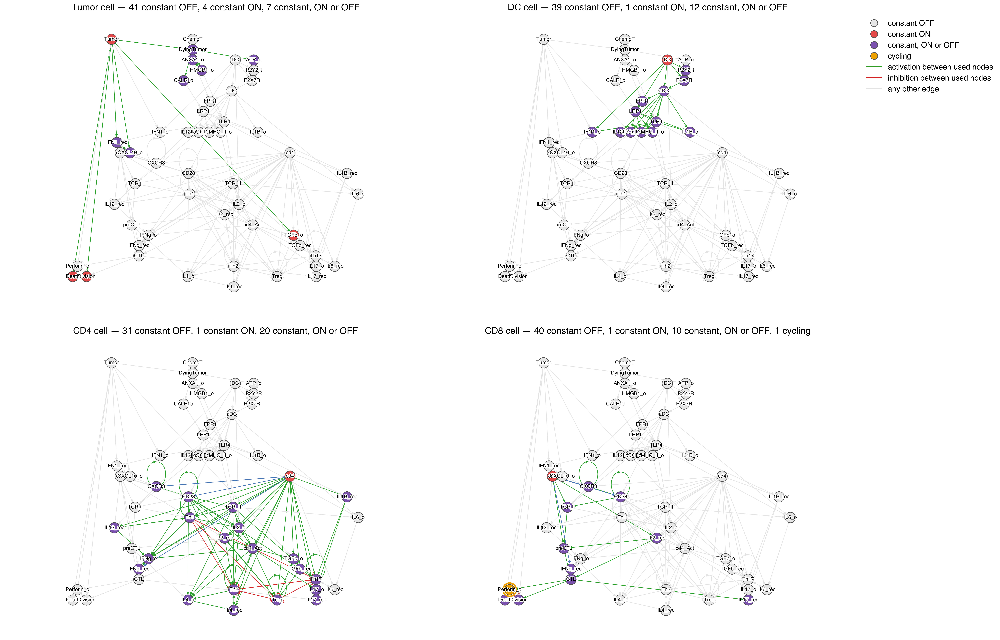

In [12]:
CLASS_COLORS = {"constant OFF": "#e6e6e6", "constant ON": "#e34948",
                "constant, ON or OFF": "#7b52ae", "cycling": STATE_COLORS["cycling"]}
FADED = "#e3e3e3"
class_handles = [
    Line2D([], [], marker="o", ls="", ms=14, mfc=c, mec="#555555", label=k)
    for k, c in CLASS_COLORS.items()
] + [Line2D([], [], color="#2ca02c", lw=2, label="activation between used nodes"),
     Line2D([], [], color="#d62728", lw=2, label="inhibition between used nodes"),
     Line2D([], [], color=FADED, lw=2, label="any other edge")]

fig, axes = plt.subplots(2, 2, figsize=(30, 22))
for ax, cell in zip(axes.flat, COMPARTMENTS):
    cls = node_class[cell]
    used = set(cls.index[cls != "constant OFF"])
    faded = {(u, v): FADED for u, v in net.edges if not (u in used and v in used)}
    counts = cls.value_counts().reindex(CLASS_ORDER).fillna(0).astype(int)
    mv.draw_network(net, ax=ax, node_size=420, node_color=cls.map(CLASS_COLORS).to_dict(),
                    edge_color=faded, highlight_nodes=cycling_nodes[cell],
                    highlight_color=STATE_COLORS["cycling"], legend=False,
                    label_kw={"font_size": 10},
                    title=f"{cell} cell — " + ", ".join(f"{v} {k}" for k, v in counts.items() if v))
    ax.title.set_fontsize(18)
axes.flat[1].legend(handles=class_handles, loc="upper left", bbox_to_anchor=(1.0, 1.0),
                    frameon=False, fontsize=15)
fig.subplots_adjust(wspace=0.02, hspace=0.08)
plot_style.save_fig(fig, "network_node_class_per_cell_type")

### Which scenario gives which outcome?

A truth table rather than a clustermap: one row per scenario (which cell types are present, and
chemotherapy), rows grouped by the pattern of four readouts that follow the ICD cascade:

`DyingTumor` (tumour) → `aDC` (DC) → `Th1` (CD4) → `CTL` (CD8),

i.e. immunogenic tumour death, DC activation, T-helper polarisation, cytotoxic T cells. Each
distinct readout pattern is a phenotype class `P1…Pn`, numbered by how many scenarios reach it
(the number of scenarios is in brackets). Within a class, the inputs that change from row to row
do not matter for that phenotype, and the inputs that stay the same define it. `n att.` counts the
attractors per row. They differ in the other nodes, mostly in the T-helper subset
(`Th2`, `Th17`, `Treg`) and in `IL1B_rec` (`IL1B_o` starts free). A `*` marks a scenario whose
attractors reach different readout patterns, i.e. multistability at the phenotype level.

Every chemotherapy scenario is marked `*` because it can also end in P1 (no ICD). In the Boolean
abstraction `ChemoT` may decay before `DyingTumor` switches on, since rates are ignored. In MaBoSS
that branch has probability $\frac{1/72}{1 + 1/72} \approx 1.4\,\%$ (`$degChemo = 1/72`,
`$effectChemo = 1`).

,n_scenarios,n_attractors,DyingTumor (tumour),aDC (DC),Th1 (CD4),CTL (CD8),Tumor_present,ChemoT_present,DC_present,CD4_present,CD8_present
phenotype,,,,,,,,,,,
1,24,36,0.0,0.0,0.0,0.0,0.67,0.33,0.5,0.5,0.5
2,4,6,1.0,0.0,0.0,0.0,1.00,1.00,0.0,0.5,0.5
3,2,2,1.0,1.0,0.0,0.0,1.00,1.00,1.0,0.0,0.5
4,1,4,1.0,1.0,1.0,1.0,1.00,1.00,1.0,1.0,1.0
5,1,4,1.0,1.0,1.0,0.0,1.00,1.00,1.0,1.0,0.0


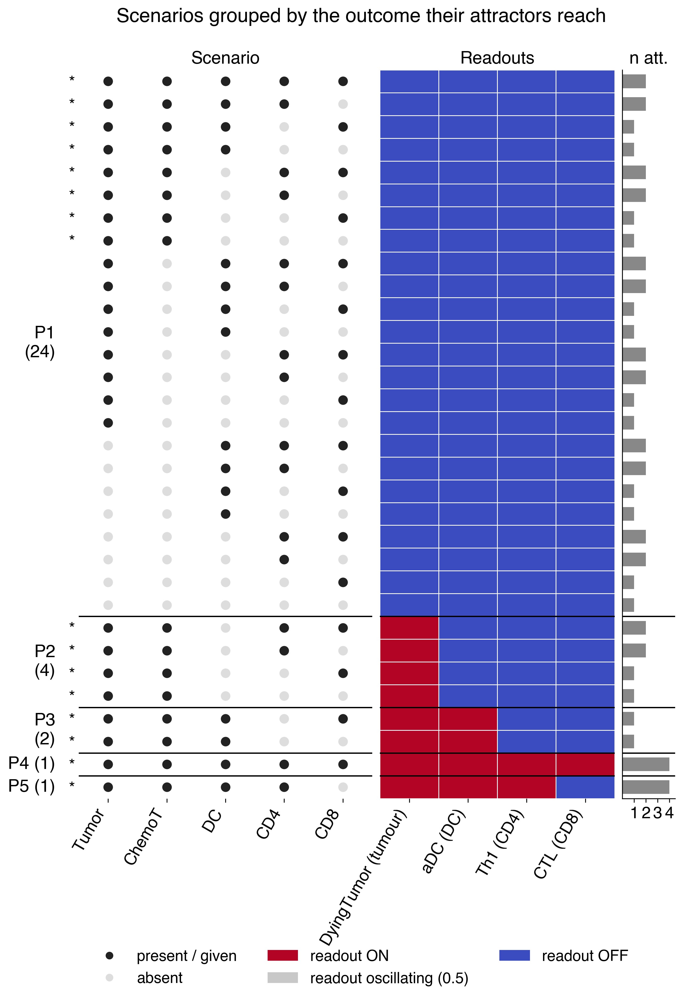

In [13]:
from matplotlib.colors import BoundaryNorm, ListedColormap

# --- Scenario -> outcome truth table ---------------------------------------------------
input_list = SCENARIO_COLS
READOUTS = {"DyingTumor__Tumor": "DyingTumor (tumour)", "aDC__DC": "aDC (DC)",
            "Th1__CD4": "Th1 (CD4)", "CTL__CD8": "CTL (CD8)"}
readout_list = list(READOUTS)

inputs = att_df[input_list].astype(int)
outputs = attractor_states[readout_list]
table = (pd.concat([inputs, outputs], axis=1)
         .groupby(input_list + readout_list, as_index=False).size()
         .rename(columns={"size": "n_attractors"}))

# Phenotype class = distinct readout pattern, numbered by how many scenarios reach it
# (ties broken by the pattern itself, so the numbering is reproducible)
pattern = table[readout_list].apply(tuple, axis=1)
counts = pattern.value_counts()
class_order = sorted(counts.index, key=lambda p: (-counts[p], tuple(-v for v in p)))
table["phenotype"] = pattern.map({p: i + 1 for i, p in enumerate(class_order)})
table = table.sort_values(["phenotype"] + input_list, ascending=[True] + [False] * len(input_list))
table = table.reset_index(drop=True)

# A scenario appearing in more than one class is multistable at the phenotype level
combo_key = table[input_list].astype(str).agg("".join, axis=1)
mixed = combo_key.duplicated(keep=False)

n_rows = len(table)
fig, (ax_in, ax_out, ax_n) = plt.subplots(
    1, 3, figsize=(10, 0.3 * n_rows + 2.6), sharey=True,
    gridspec_kw={"width_ratios": [len(input_list), len(readout_list), 0.9], "wspace": 0.04},
)
y = np.arange(n_rows)

# Inputs: dot matrix (filled = present / given)
for j, name in enumerate(input_list):
    on = table[name].to_numpy() == 1
    ax_in.scatter(np.full(on.sum(), j), y[on], s=60, color="#222222", zorder=3)
    ax_in.scatter(np.full((~on).sum(), j), y[~on], s=60, color="#dddddd", zorder=3)
ax_in.set_xlim(-0.5, len(input_list) - 0.5)
ax_in.set_xticks(range(len(input_list)))
ax_in.set_xticklabels(input_list, rotation=60, ha="right", fontsize=15)
ax_in.set_title("Scenario", fontsize=16)

# Readouts: OFF / oscillating (0.5) / ON
state_cmap = ListedColormap(["#3b4cc0", "#c8c8c8", "#b40426"])
state_norm = BoundaryNorm([-0.25, 0.25, 0.75, 1.25], state_cmap.N)
ax_out.pcolormesh(
    np.arange(len(readout_list) + 1) - 0.5, np.arange(n_rows + 1) - 0.5,
    table[readout_list].to_numpy(), cmap=state_cmap, norm=state_norm,
    edgecolors="white", linewidth=0.6,
)
ax_out.set_xticks(range(len(readout_list)))
ax_out.set_xticklabels([READOUTS[r] for r in readout_list], rotation=60, ha="right", fontsize=15)
ax_out.set_title("Readouts", fontsize=16)

# Number of attractors per row (>1 = multistable with identical readouts)
ax_n.barh(y, table["n_attractors"], height=0.6, color="#888888")
ax_n.set_xlim(0, table["n_attractors"].max() + 0.5)
ax_n.set_xticks(range(1, table["n_attractors"].max() + 1))
ax_n.set_title("n att.", fontsize=16)
ax_n.spines[["top", "right"]].set_visible(False)
ax_n.tick_params(axis="x", labelsize=15)

# Phenotype class separators and labels
bounds = np.flatnonzero(np.diff(table["phenotype"].to_numpy())) + 0.5
for ax in (ax_in, ax_out, ax_n):
    for b in bounds:
        ax.axhline(b, color="black", linewidth=1.2)
    ax.tick_params(axis="y", length=0)
for cls, rows_ in table.groupby("phenotype").groups.items():
    mid = (rows_.min() + rows_.max()) / 2
    sep = "\n" if len(rows_) > 1 else " "   # single-row classes: one line, so labels do not overlap
    ax_in.text(-0.9, mid, f"P{cls}{sep}({len(rows_)})", ha="right", va="center", fontsize=16,
               fontweight="bold")
ax_in.set_yticks(y)
ax_in.set_yticklabels(["*" if m else "" for m in mixed], fontsize=15)  # * = scenario reaches >1 class
ax_in.set_ylim(n_rows - 0.5, -0.5)
for ax in (ax_in, ax_out):
    ax.spines[:].set_visible(False)

fig.legend(
    handles=[
        Line2D([], [], marker="o", linestyle="", color="#222222", label="present / given"),
        Line2D([], [], marker="o", linestyle="", color="#dddddd", label="absent"),
        Patch(facecolor="#b40426", label="readout ON"),
        Patch(facecolor="#c8c8c8", label="readout oscillating (0.5)"),
        Patch(facecolor="#3b4cc0", label="readout OFF"),
    ],
    loc="lower center", ncol=3, frameon=False, fontsize=14, bbox_to_anchor=(0.5, -0.04),
)
fig.suptitle("Scenarios grouped by the outcome their attractors reach", y=0.995, fontsize=18)
fig.subplots_adjust(left=0.14, bottom=0.17, top=0.93)
plot_style.save_fig(fig, "scenario_outcome_table")

# Text version: readouts of each class, and the fraction of its scenarios with each input
summary = table.groupby("phenotype").agg(
    n_scenarios=("n_attractors", "size"),
    n_attractors=("n_attractors", "sum"),
    **{READOUTS[r]: (r, "first") for r in readout_list},
    **{f"{n}_present": (n, "mean") for n in input_list},
)
summary.round(2)

### The same classes on the reachability diagram

This replaces the succession diagram. Attractors are computed from the initial states rather than
from the whole state space, so the diagram is root → one node per scenario (labelled with the
cell types present) → the attractors reached from it. It is drawn with graphviz `dot`. Leaves are
filled with their phenotype class `P1…Pn` and labelled with it. Scenario nodes are tinted with the
class of their attractors, or grey if those disagree. Nodes are ordered by class before layout so
each class forms one contiguous block. Set `RANKDIR = "TB"` for a top-to-bottom tree.

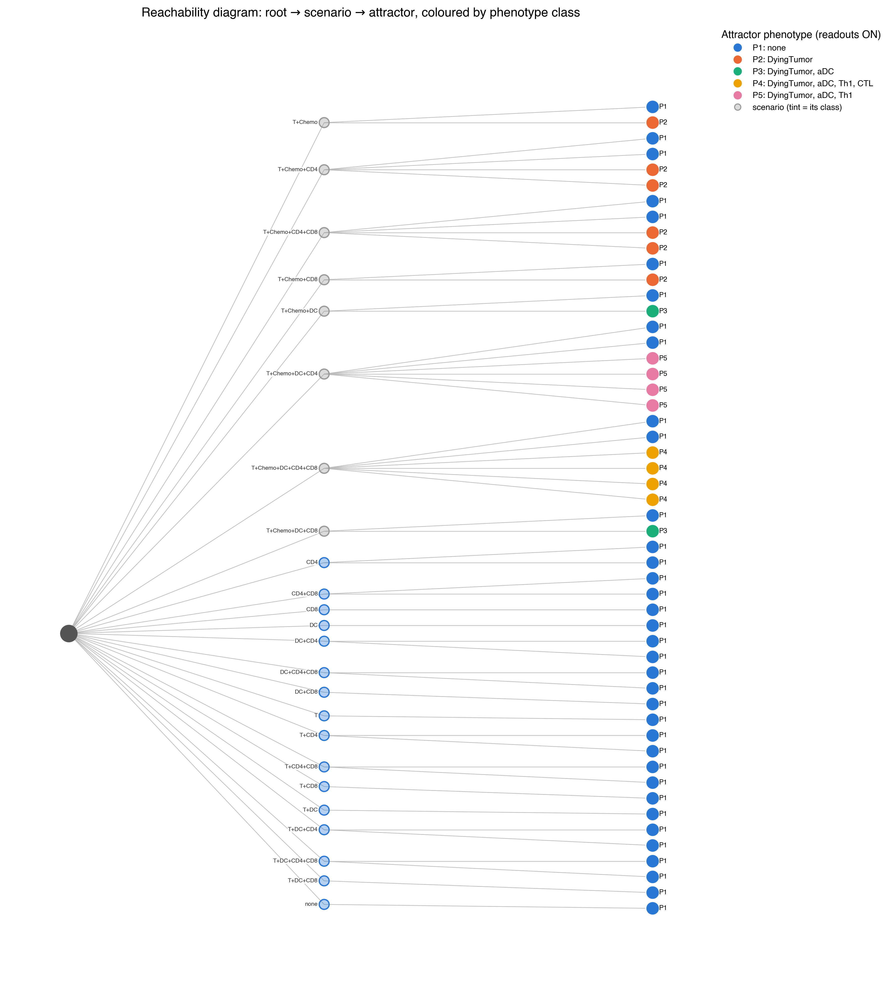

In [14]:
from matplotlib.colors import to_rgba

# --- Reachability diagram, attractors coloured by phenotype class ------------------------
RANKDIR = "LR"
class_colors = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300",
                "#4a3aa7", "#e34948", "#7f7f7f", "#17becf"]  # fixed categorical order; slot i -> P(i+1)
pattern_to_class = {tuple(row[readout_list]): int(row["phenotype"]) for _, row in table.iterrows()}
assert len(pattern_to_class) <= len(class_colors), "add colours for the extra classes"
leaf_class = {a: pattern_to_class[tuple(attractor_states.loc[a, readout_list])] for a in att_df.index}

G = nx.DiGraph()
G.add_node("root")
for a, sc in att_df["scenario"].items():
    G.add_edge("root", sc)
    G.add_edge(sc, a)
leaves = list(att_df.index)
combos = list(G.successors("root"))

# Scenario nodes take the class of their attractors when they all agree (None = mixed)
subtree_class = dict(leaf_class)
for sc in combos:
    reached = {leaf_class[a] for a in G.successors(sc)}
    subtree_class[sc] = reached.pop() if len(reached) == 1 else None
subtree_class["root"] = None


# Re-insert nodes in (class, scenario) order so `dot` draws each class as a block
def sort_key(n):
    return (subtree_class[n] or 0, n)


H = nx.DiGraph()
H.add_nodes_from(sorted(G, key=sort_key))
for parent in H.nodes:
    H.add_edges_from((parent, child) for child in sorted(G.successors(parent), key=sort_key))
pos = nx.nx_agraph.graphviz_layout(H, prog="dot",
                                   args=f"-Grankdir={RANKDIR} -Gordering=out -Gnodesep=0.05 -Granksep=3")


def fill(n, alpha=1.0):
    c = subtree_class[n]
    return to_rgba(class_colors[c - 1], alpha) if c else to_rgba("#9a9a9a", alpha)


fig, ax = plt.subplots(figsize=(12, 0.22 * len(leaves) + 2) if RANKDIR == "LR"
                       else (0.22 * len(leaves) + 2, 10))
nx.draw_networkx_edges(H, pos, ax=ax, edge_color="#bbbbbb", width=0.6, arrows=False)
nx.draw_networkx_nodes(H, pos, nodelist=["root"], ax=ax, node_color="#555555", node_size=250)
nx.draw_networkx_nodes(H, pos, nodelist=combos, ax=ax, node_size=90,
                       node_color=[fill(n, 0.35) for n in combos],
                       edgecolors=[fill(n) for n in combos], linewidths=1.2)
nx.draw_networkx_nodes(H, pos, nodelist=leaves, ax=ax, node_size=170,
                       node_color=[fill(n) for n in leaves], edgecolors="white", linewidths=1.0)

# Leaf labels: phenotype class (identity is never colour-only)
for n in leaves:
    x, y_ = pos[n]
    ax.text(x + 9, y_, f"P{leaf_class[n]}", ha="left", va="center", fontsize=6.5)
# Scenario labels: which cell types are present
for n in combos:
    x, y_ = pos[n]
    ax.text(x - 9, y_, n, ha="right", va="center", fontsize=5.5, color="#333333",
            bbox=dict(boxstyle="square,pad=0.05", fc="white", ec="none", alpha=0.8))

def class_label(c):
    # "P3: DyingTumor, aDC (oscillating: CTL)": readouts ON / oscillating in class c
    values = dict(zip((r.split("__")[0] for r in readout_list), class_order[c - 1]))
    on = [r for r, v in values.items() if v == 1]
    osc = [r for r, v in values.items() if v == 0.5]
    return f"P{c}: " + (", ".join(on) or "none") + (f" (oscillating: {', '.join(osc)})" if osc else "")


ax.legend(
    handles=[Line2D([], [], marker="o", linestyle="", markersize=7, color=class_colors[c - 1],
                    label=class_label(c)) for c in sorted(table["phenotype"].unique())]
    + [Line2D([], [], marker="o", linestyle="", markersize=6, markerfacecolor=to_rgba("#9a9a9a", 0.35),
              markeredgecolor="#9a9a9a", label="scenario (tint = its class)")],
    title="Attractor phenotype (readouts ON)", loc="upper left", bbox_to_anchor=(1.0, 1.0),
    frameon=False, fontsize=8,
)
ax.set_title("Reachability diagram: root → scenario → attractor, coloured by phenotype class")
ax.set_axis_off()
fig.tight_layout()
plot_style.save_fig(fig, "reachability_diagram_phenotype")

### Phenotype classes on the regulatory network

Each attractor gets the label of its phenotype class `P1…Pn` from the truth table above. The
network has one node per model node, not per cell type, so each attractor is first projected to
the population: a node is ON if it is ON in at least one cell type (the `p[(X) = (1)]` of
UPMaBoSS), and 0.5 if it only oscillates. Averaging over the attractors of a class gives one
consensus activity profile per phenotype, which is drawn on the Step 1 layout.

A value of **0.5 is ambiguous**: the node may oscillate inside the attractors, or be ON in half of
them and OFF in the rest. Scenario inputs that vary within a class (see the summary table above)
show intermediate values for the same reason.

In [15]:
# --- Label every attractor with its phenotype class (same mapping as the truth table) ---
phenotype_order = [f"P{c}" for c in sorted(table["phenotype"].unique())]
phenotype = pd.Series(pd.Categorical([f"P{leaf_class[a]}" for a in att_df.index],
                                     categories=phenotype_order), index=att_df.index, name="phenotype")
phenotype.value_counts(sort=False)

phenotype
P1    36
P2     6
P3     2
P4     4
P5     4
Name: count, dtype: int64

In [16]:
# --- Population projection, then consensus profile of each class -----------------------
population_states = pd.DataFrame(
    {n: attractor_states[[var(n, c) for c in COMPARTMENTS]].max(axis=1) for n in nodes})
phenotype_activity = population_states.groupby(phenotype, observed=True).mean()
phenotype_activity[["Tumor", "ChemoT", "DC", "cd4", "cd8", "DyingTumor", "aDC", "Th1", "Th2",
                    "Th17", "Treg", "CTL", "Perforin_o"]].round(2)

,Tumor,ChemoT,DC,cd4,cd8,DyingTumor,aDC,Th1,Th2,Th17,Treg,CTL,Perforin_o
phenotype,,,,,,,,,,,,,
P1,0.67,0.0,0.5,0.67,0.5,0.0,0.0,0.0,0.00,0.00,0.00,0.0,0.0
P2,1.00,0.0,0.0,0.67,0.5,1.0,0.0,0.0,0.00,0.00,0.00,0.0,0.0
P3,1.00,0.0,1.0,0.00,0.5,1.0,1.0,0.0,0.00,0.00,0.00,0.0,0.0
P4,1.00,0.0,1.0,1.00,1.0,1.0,1.0,1.0,0.25,0.25,0.25,1.0,0.5
P5,1.00,0.0,1.0,1.00,0.0,1.0,1.0,1.0,0.25,0.25,0.25,0.0,0.0


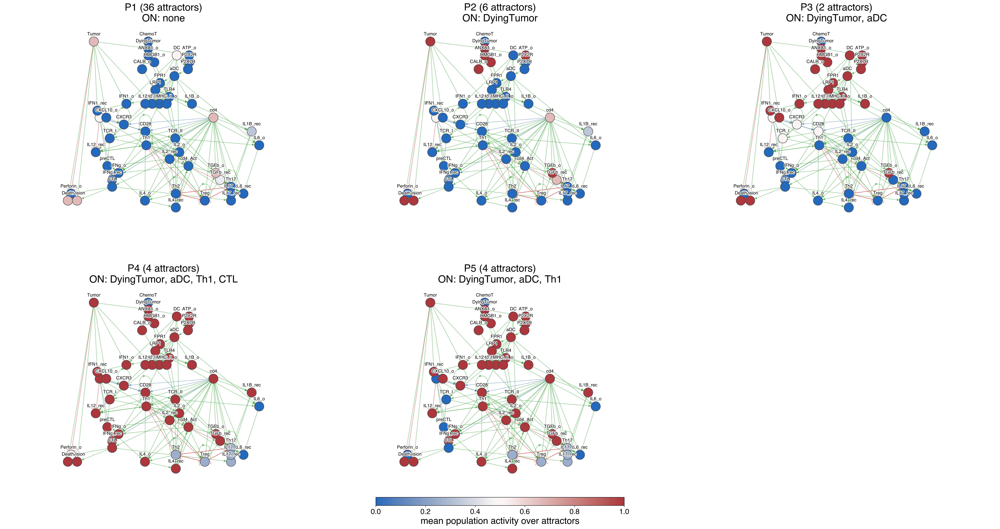

In [17]:
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

class_size = phenotype.value_counts()


def describe(p):
    # Title text: readouts ON in class `p`, then those oscillating
    out = phenotype_activity.loc[p, [r.split("__")[0] for r in readout_list]]
    text = "ON: " + (", ".join(out.index[out == 1]) or "none")
    free = out.index[(out > 0) & (out < 1)]
    return text + ("\nmixed / oscillating: " + ", ".join(free) if len(free) else "")


# One panel per class; `time=` picks a row of the activity table by its index label
NCOLS = 3
nrows = -(-len(phenotype_order) // NCOLS)
fig, axes = plt.subplots(nrows, NCOLS, figsize=(13 * NCOLS, 11 * nrows), squeeze=False)
for i, (p, ax) in enumerate(zip(phenotype_order, axes.flat)):
    # Per-panel colorbars off (one shared below); edge legend only on the top-right panel
    mv.plot_activity(net, phenotype_activity, time=p, cmap="vlag", size_by=False,
                     node_size=420, ax=ax, colorbar=False, legend=(i == NCOLS - 1),
                     label_kw={"font_size": 10},
                     title=f"{p} ({class_size[p]} attractors)\n{describe(p)}")
    ax.title.set_fontsize(22)
    if ax.get_legend():
        plt.setp(ax.get_legend().get_texts(), fontsize=16)
for ax in axes.flat[len(phenotype_order):]:
    ax.set_visible(False)

fig.subplots_adjust(wspace=0.05, hspace=0.3)
cbar = fig.colorbar(ScalarMappable(norm=Normalize(0, 1), cmap="vlag"), ax=axes,
                    location="bottom", shrink=0.25, pad=0.02, aspect=30)
cbar.set_label("mean population activity over attractors", fontsize=20)
cbar.ax.tick_params(labelsize=16)
plot_style.save_fig(fig, "phenotype_activity_grid")
plt.show()